In [84]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster


These are the raw (ish) results. The jira2prov columns are derived from the names of jira issue fields changed in edits to the issue.

In [85]:
results=pd.read_csv("user_activity_merged.csv",index_col='agent')
results["total"]=results.sum(axis=1)
# results

These fields are too granular, which makes the data very sparse and skewed. There are 35 columns, many of which are mostly zero.
There are also a lot of agents with not very much activity. Any clustering carried out on this in its current form is going to be influenced by activity levels rather than types. It is unlikely that we will see stable clusters.
Mitigation:
- inspect the jira fields that form the basis of the activity types and where the fields represent a similar type of activity, merge them into a new field
- After the merge/s, remove users with avery low levels of activity. These can be treated as their own separate 'sparse activity" cluster, and inspected for any interesting patterns:
These are the merged fields
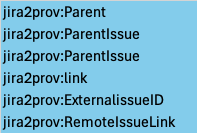

In [86]:
issue_link = ["jira2prov:Parent", "jira2prov:ParentIssue", "jira2prov:ParentIssue", "jira2prov:Link",
                  "jira2prov:ExternalissueID", "jira2prov:RemoteIssueLink"]
issue_progress = ["jira2prov:status", "jira2prov:Workflow", "jira2prov:resolution"]
categorising = ["jira2prov:labels", "jira2prov:priority", "jira2prov:issuetype"]
dev_process = ["jira2prov:FixVersion", "jira2prov:Version", "jira2prov:Component", "jira2prov:Milestone",
                   "jira2prov:Sprint"]
issue_content = ["jira2prov:description", "jira2prov:Attachment", "jira2prov:summary"]
comment_activity = ["jira2prov:comment", "jira2prov:Comment"]
merges = {"issue_link": issue_link, "issue_progress": issue_progress, "categorising": categorising,
              "dev_process": dev_process, "issue_content": issue_content, "comment_activity": comment_activity}

merged_results = results.copy()
# drop superfluous columns
merged_results=merged_results.drop(columns=['issue_comments',  'jira2prov:Rang', 'issues_opened', 'labels_issue',])

for merge in merges:
    merged_results[merge] = merged_results[merges[merge]].sum(axis=1)
    merged_results = merged_results.drop(columns=merges[merge],inplace=False)
print(merged_results.columns)
# merged_results

Index(['jira2prov:assignee', 'closed_pull', 'commits_started', 'labels_pull',
       'pr_comments', 'pull_reqs_opened', 'referred_pull_comments',
       'agent_mentioned', 'mentions_users', 'refs_issues', 'total',
       'issue_link', 'issue_progress', 'categorising', 'dev_process',
       'issue_content', 'comment_activity'],
      dtype='object')


# Data Cleaning
Separate out sparse users...

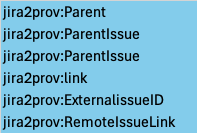

In [87]:
# fix the two dependabots. One of the depandabots came from a jira json response that was urlencoded, resulting in a separate agent
merged_results = merged_results.rename(index={"github:dependabot%5Bbot%5D": "github:dependabot"})
merged_results = merged_results.groupby(level=0).sum()

# separate out people with less than C contributions
C = 10
mask = merged_results["total"] >= C
sparse_contributors = merged_results[~mask]
merged_results = merged_results[mask]
merged_results=merged_results.drop(columns=['total',])

# dropping these because they could each be more than one user. They also seem to be outliers and the clusters look better without them
merged_results = merged_results.drop(labels=['pars:unknown_user', 'pars:anonymous', 'pars:unknown'],axis=0, errors='ignore')
# standarise the variables

As things stand some variables are massively skewed and have large range. This will tend to cluster contributors on the volume rather than type of activity they do. To address this, we standardise the variables using row proportions. i.e. divide each variable value by the sum of its varable values. This emphasises the types of activities a contributor does over the quantity. We will also do a Square root transform, which will further improve matters by smoothing out the distribution, reducing very large values while preserving rank.

In [88]:
# transform all the data using row proprtions, so that all the variable have the same range and each column sums to 1
row_sums=merged_results.sum(axis="columns")
std_results = merged_results.div(row_sums, axis="index")
transformed_results = np.sqrt(std_results)
# transformed_results

# Clustering!
We are using agglomerative (top down merges to clusters) clustering just because...  @TODO why, by not divisive (bottom up splits)?
We can use Euclidean or bray-curtis distance.
Euclidean distance uses squared diffs and works with non-negative values. It is more sensitive to changes in magnitude.
Bray-curtis assumes non-negative values and doesn't rely on squared diffs. it is therefore less sensitive to magnitude.
The Ward method is sometime questioned when used with braycurtis. However We converted activity counts to row proportions (focus on activity profiles rather than total volume),  sqrt transformed so that Euclidean distance would provide a better measure of dissimilarity between profiles prior to hierarchical clustering.
To see the difference, change the 'metric' parameter on line 4

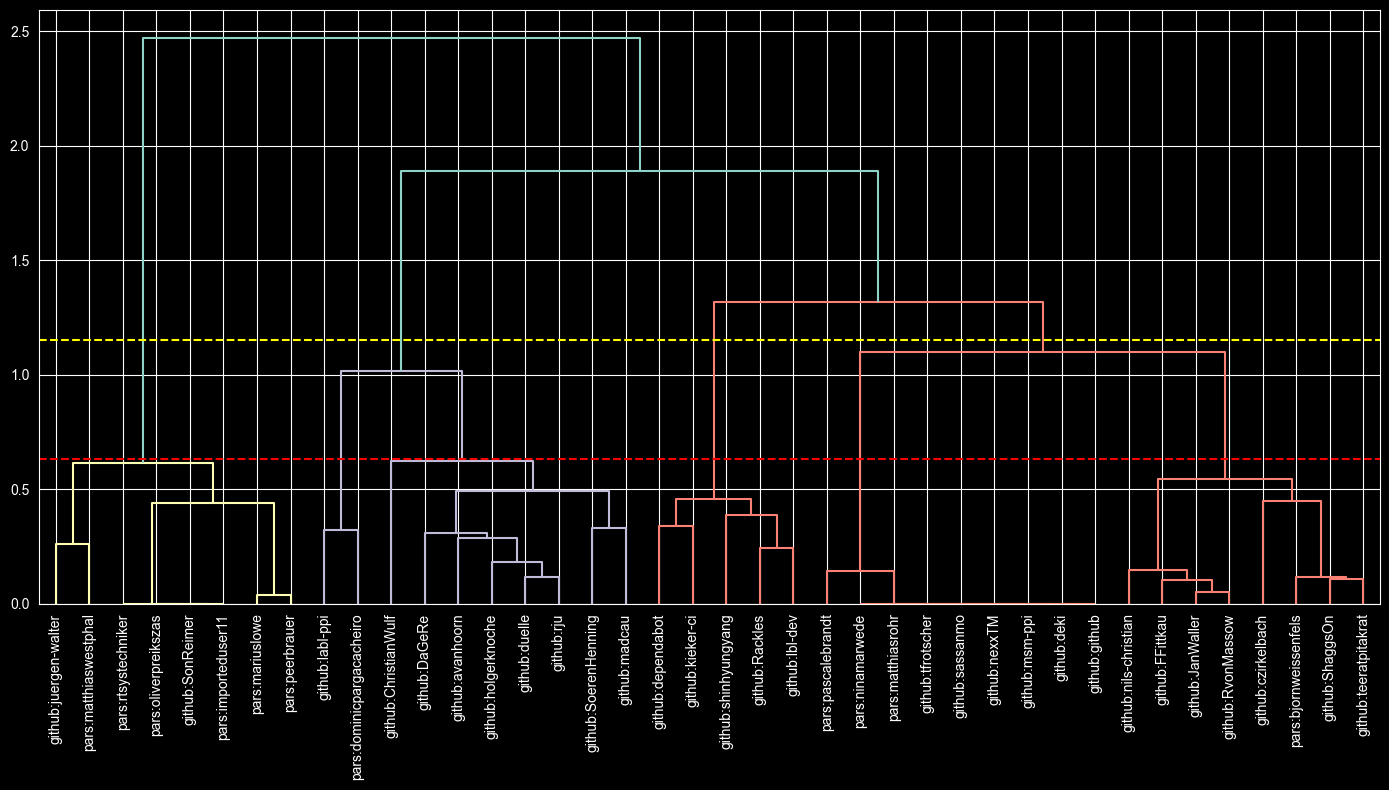

In [89]:
from scipy.cluster.hierarchy import dendrogram
from scipy.spatial.distance import pdist
# claculate (yes this is a word now!) the distances.we use bray-curtis as a distance metric because it doesnt use square values and so is less sensitive to magnitude.
e_dist = pdist(transformed_results, metric="braycurtis")

# do the clustering - we are using the ward method for calculating distances between clusters. To calculate the distances between two clusters it looks at how the variance changes if the clusters are merged.
clusters = linkage(e_dist, method="ward")

plt.figure(figsize=(14, 8))
# make a tree
tree = dendrogram(clusters, labels=transformed_results.index.tolist(), leaf_rotation=90, leaf_font_size=10)

# reorder dataframe rows to match dendrogram leaf order
ordered_results = transformed_results.iloc[tree["leaves"]]

# reorder the column variables to group them into meaningful groups--
variables_order = [
                # issue and PR progressing, dev workflows
                    'pull_reqs_opened',
                    'closed_pull',
                    'jira2prov:assignee',   # from here down to 'issue_link' it's jira2prov /issue related, so pre-Git users should go dark in this region
                    'dev_process',          #   |
                    'issue_progress',       #   |
                    'issue_content',        #   |
                    'refs_issues',          #   |
                    'issue_link',           #       end of the issue related region
                #categorising, content labelling
                    'categorising',
                    'labels_pull',
                #communicating, referencing
                    'referred_pull_comments',
                    'mentions_users',
                #commenting
                    'pr_comments',
                    'comment_activity',
                #being referred to
                    'agent_mentioned',
                # writing code
                    'commits_started',
                ]

# reorder the variables to group them by similarity for a better heatmap
ordered_results =  ordered_results[variables_order]

plt.axhline(y=0.63, color="red", linestyle="--")
plt.axhline(y=1.15, color="yellow", linestyle="--")
plt.tight_layout()
plt.show()

# Heatmap
This heatmap has users arranged on the Y-Axis in the same order as the leaves on the dendrogram. This means users are grouped together by similarity, so we get a visual representation of which activities they are grouped by.

['github:juergen-walter', 'pars:matthiaswestphal', 'pars:rtsystechniker', 'pars:oliverpreikszas', 'github:SonReimer', 'pars:importeduser11', 'pars:mariuslowe', 'pars:peerbrauer', 'github:labl-ppi', 'pars:dominicpargacacheiro', 'github:ChristianWulf', 'github:DaGeRe', 'github:avanhoorn', 'github:holgerknoche', 'github:duelle', 'github:rju', 'github:SoerenHenning', 'github:madcau', 'github:dependabot', 'github:kieker-ci', 'github:shinhyungyang', 'github:Rackles', 'github:lbl-dev', 'pars:pascalebrandt', 'pars:ninamarwede', 'pars:matthiasrohr', 'github:tfrotscher', 'github:sassanmo', 'github:nexxTM', 'github:msm-ppi', 'github:deki', 'github:github', 'github:nils-christian', 'github:FFittkau', 'github:JanWaller', 'github:RvonMassow', 'github:czirkelbach', 'pars:bjornweissenfels', 'github:ShaggsOn', 'github:teeratpitakrat']


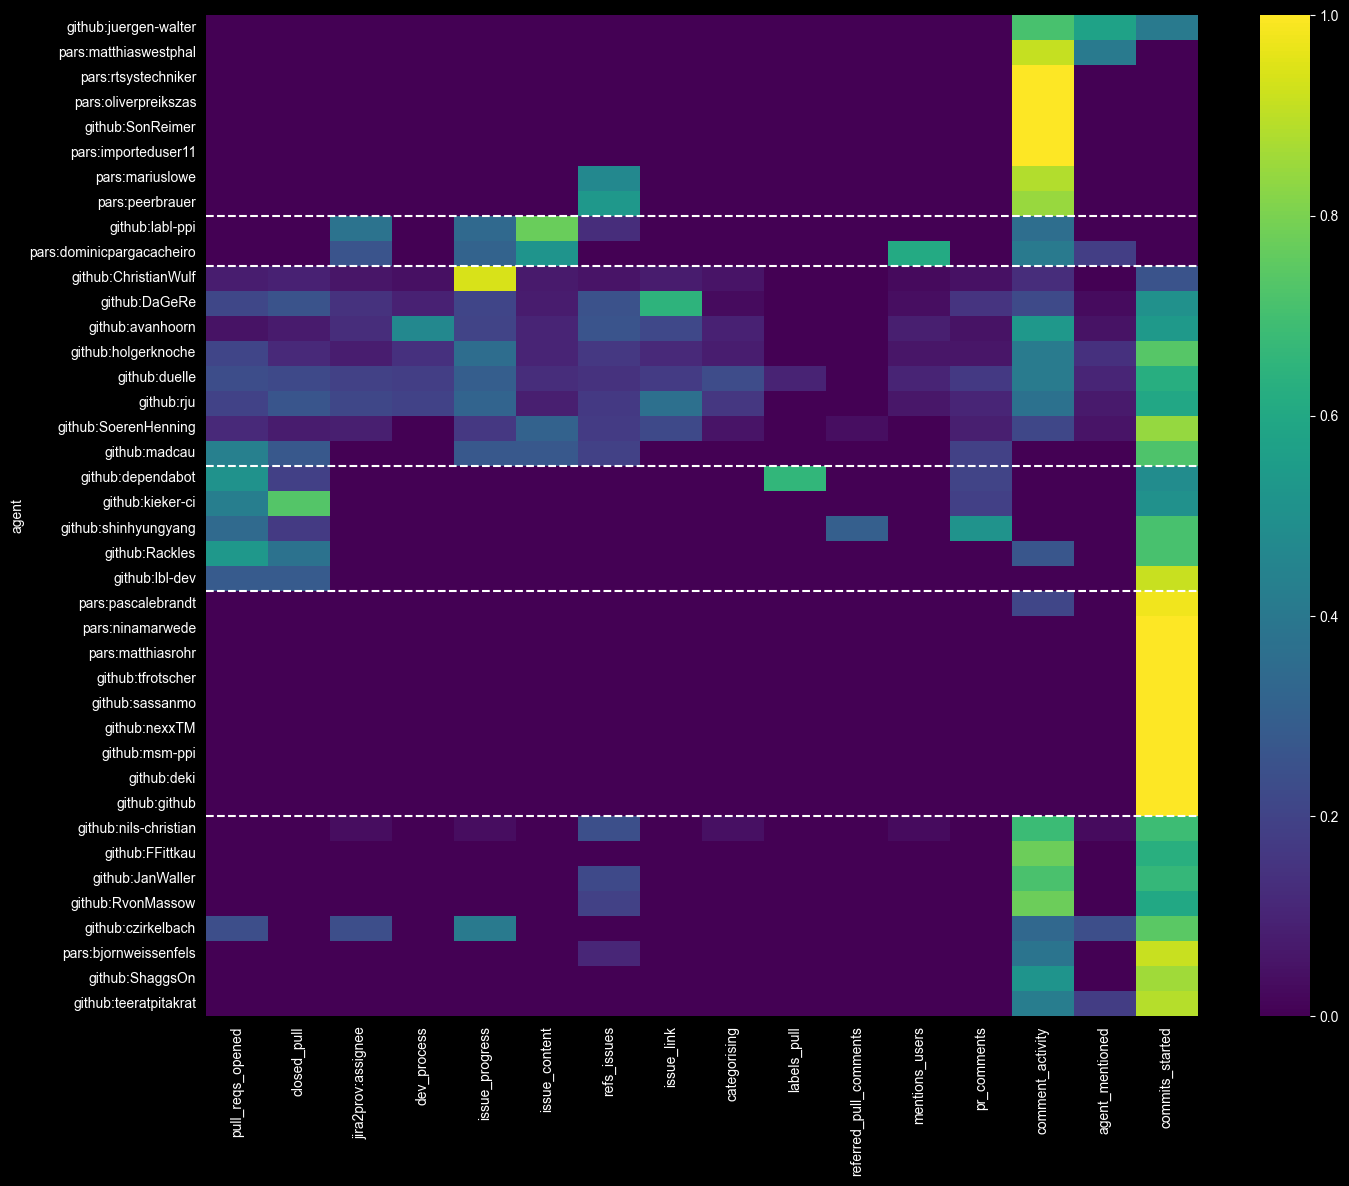

In [96]:
# heatmap using data with the agents in the same order as the dendrogram leaves, i.e
plt.figure(figsize=(16, 13))
# ...using the ordered results from the last cell.
hmp=sns.heatmap(ordered_results, cmap="viridis",yticklabels=1,xticklabels=1)
hmp.axhline(10, color="white", linestyle="--")
hmp.axhline(8, color="white", linestyle="--")
hmp.axhline(18, color="white", linestyle="--")
hmp.axhline(23, color="white", linestyle="--")
hmp.axhline(32, color="white", linestyle="--")
# hmp.axhline(33, color="white", linestyle="--")
# print (ordered_results.index.tolist())
plt.show()

# merge heights
Look for the "elbow" that tells us where the best cut would be.
There are two candidates.
  - The red line gives us 6 clusters
  - The yellow line gives us 4
The red elbow is the most pronounced and also generates clusters that are better separated and aligned with the heatmap

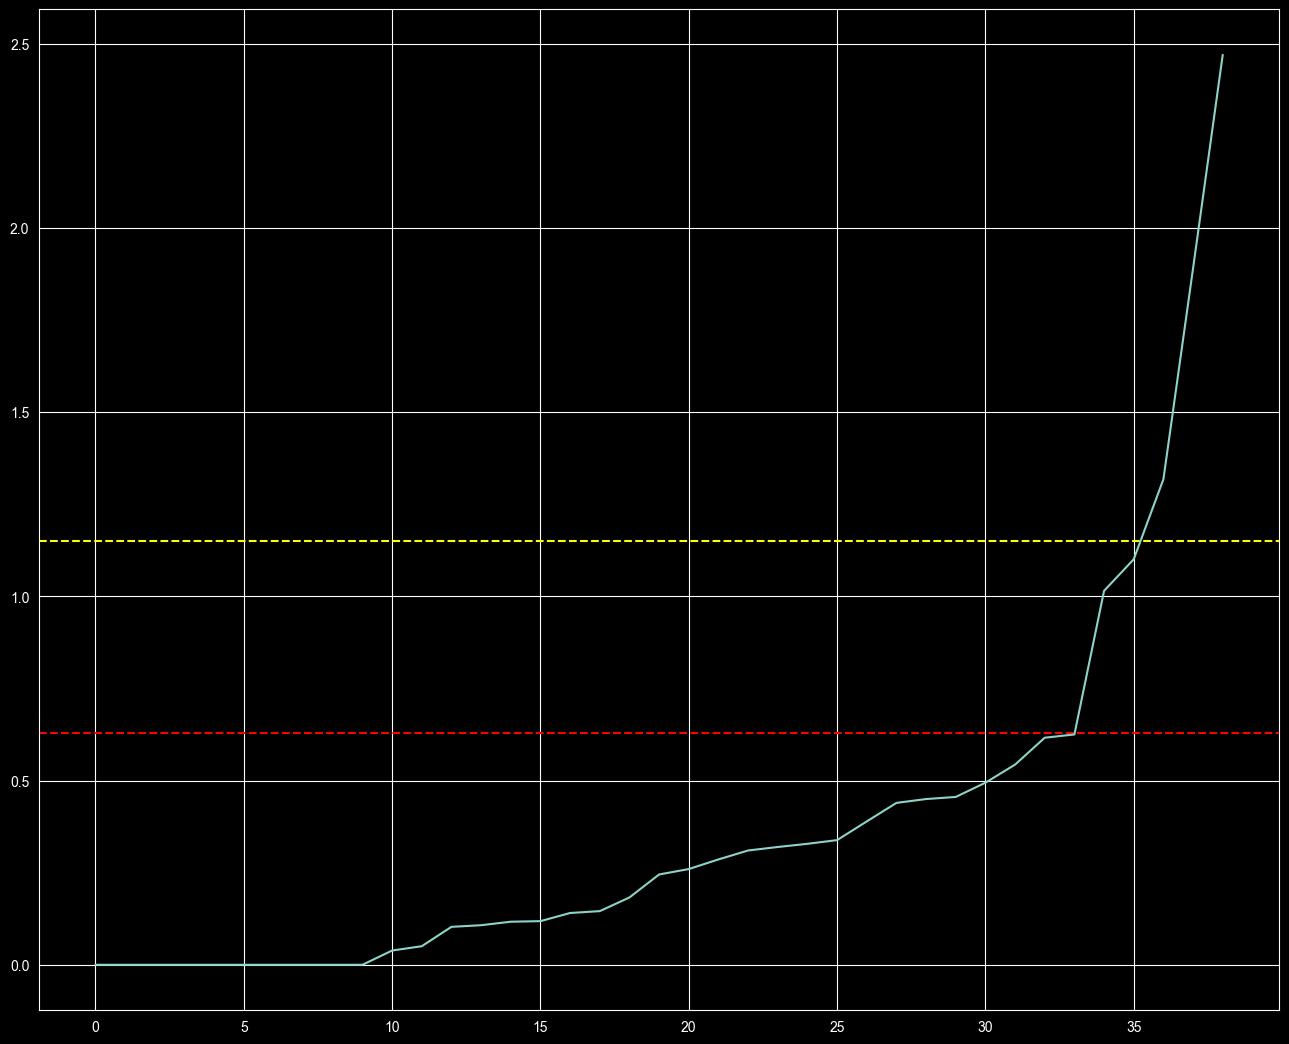

In [91]:
merge_heights=clusters[:,2]
sorted_merge_heights=sorted(merge_heights)
plt.figure(figsize=(16, 13))
plt.axhline(y=0.63, color="red", linestyle="--")
plt.axhline(y=1.15, color="yellow", linestyle="--")
plt.plot(sorted_merge_heights)

So let's generate our actual cluster memberships...

In [98]:
from scipy.cluster.hierarchy import fcluster
cut_height = 0.63
cluster_labels = fcluster(clusters, t=cut_height, criterion="distance")
cluster_results_df = transformed_results.copy()
cluster_results_df["cluster"] = cluster_labels
c = cluster_results_df["cluster"]
# cluster_results_df
c.to_csv("cluster_membership.csv")

In [97]:
cluster_profiles = cluster_results_df.groupby("cluster").mean(numeric_only=True)
# print(cluster_profiles)
cluster_profiles
# cluster_profiles.to_csv('clusterProfiles.csv')